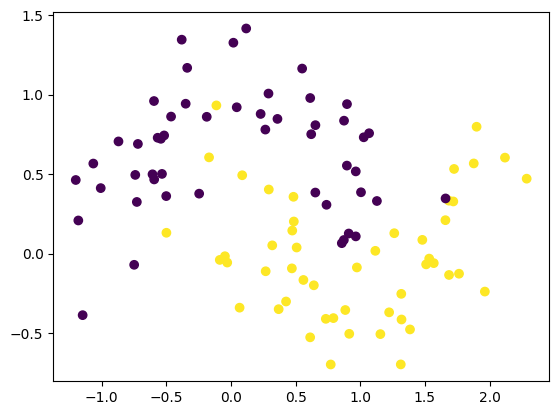

In [ ]:
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt

# 1. 데이터 불러오기
# data = make_moons(n_samples=100, noise=1, random_state=3)
# print(data[0])
# print(data[1])
x,y = make_moons(n_samples=100, noise=0.25, random_state=3)
# 2. 데이터 확인
plt.scatter(x[:,0],x[:,1], c=y)
plt.show()

In [ ]:
# 3. 데이터 분리
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
x_train,x_test,y_train,y_test = train_test_split(x,y, random_state=45, stratify=y)

# 4. 학습 - 의사결정 나무
tree = DecisionTreeClassifier(max_depth=3).fit(x_train,y_train)
print(f'tree score : {tree.score(x_test, y_test):.2f}')

tree score : 0.80


[0 0 0 ... 1 1 1]


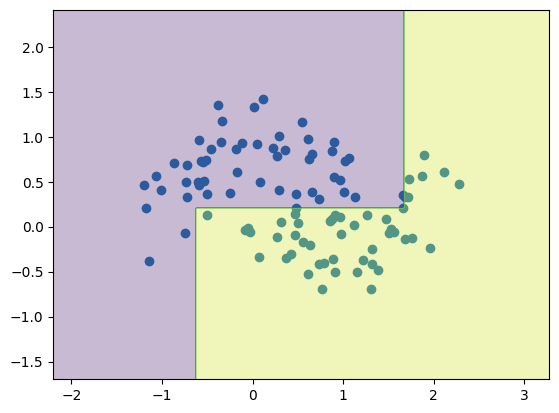

In [ ]:
# 5. 어떤방식으로 분류 했는지?
import numpy as np
draw_area(x,y,tree)

In [ ]:
def draw_area(x,y,model):
  # 1. 그래프의 x,y 축의 범위 설정
  x_min,x_max = x[:,0].min()-1, x[:,0].max()+1
  y_min,y_max = x[:,1].min()-1, x[:,1].max()+1

  # 2. 만든 범위를 0.01 간격으로 촘촘한 값을 생성
  pos_x = np.arange(x_min,x_max,0.01)
  pos_y = np.arange(y_min,y_max,0.01)
  # print(f'pos X : {pos_x}')
  # print(f'pos Y : {pos_y}')

  # 3. 격자 형태로 x,y 배열을 만든다.
  xx,yy = np.meshgrid(pos_x, pos_y)

  # 4. 두 배열을 합쳐서 일렬로 만들어 준다.
  # 두 배열을 합칠때 각각 1차원 이어야 하는데 xx, yy 는 2차원이다.
  # 그래서 ravel() 함수를 통해 1차원으로 만든다.
  val = np.c_[xx.ravel(),yy.ravel()]
  # print(val) # [[x,y],[x,y],...]

  # 5. 이렇게 생성된 값으로 모델에 예측을 시킨다.
  z = model.predict(val)
  # print(z)

  # 6. 영역을 그려준다.
  plt.scatter(x[:,0],x[:,1])
  plt.contourf(xx,yy,z.reshape(xx.shape),alpha=0.3)
  plt.show()

forest score : 0.84
[0 0 0 ... 1 1 1]


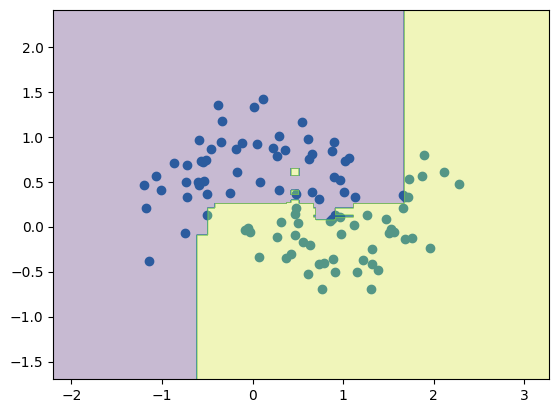

In [ ]:
# 랜덤포레스트
import sklearn.ensemble as en

# n_estimators= tree 의 갯수(개의 트리를 통해 구한 내용을 평균으로 구해 과적합을 피한다.)
# random_state= random 하게 무엇을 한다? feature 를...
# 강력한 속성 하나를 가지고 모든 트리가 판단하지 않도록 적용 속성 종류에 랜덤성을 부여
forest = en.RandomForestClassifier(n_estimators=5, random_state=2).fit(x_train,y_train)
print(f'forest score : {forest.score(x_test,y_test)}')
draw_area(x,y,forest)

trees : [DecisionTreeClassifier(max_features='sqrt', random_state=1872583848), DecisionTreeClassifier(max_features='sqrt', random_state=794921487), DecisionTreeClassifier(max_features='sqrt', random_state=111352301), DecisionTreeClassifier(max_features='sqrt', random_state=1853453896), DecisionTreeClassifier(max_features='sqrt', random_state=213298710)]
[0. 0. 0. ... 1. 1. 1.]


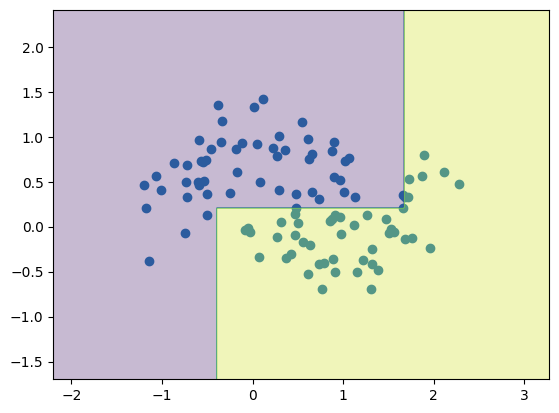

[0. 0. 0. ... 1. 1. 1.]


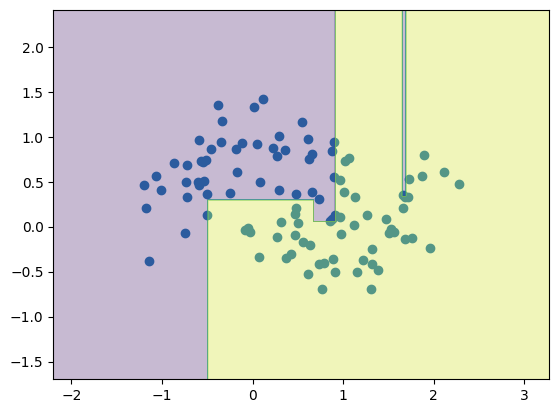

[0. 0. 0. ... 1. 1. 1.]


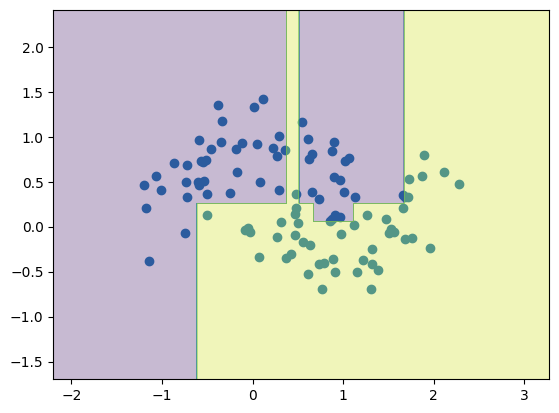

[1. 1. 1. ... 1. 1. 1.]


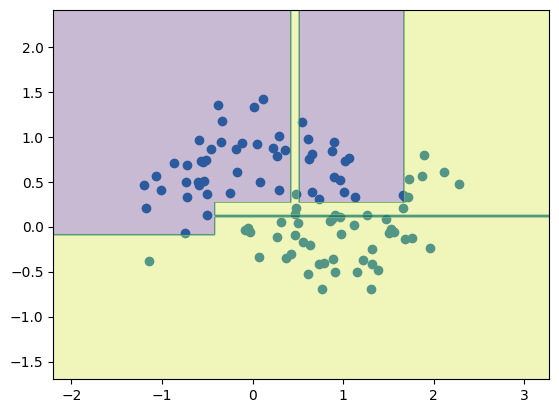

[1. 1. 1. ... 0. 0. 0.]


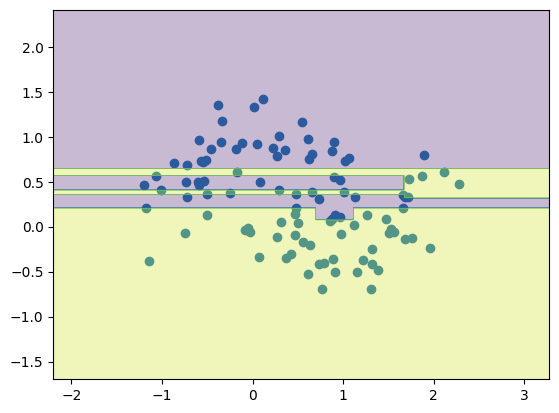

In [ ]:
# 개별 트리는 어떻게 판단했는지(개별 트리모델들에 대한 정보)
print(f'trees : {forest.estimators_}')

for model in forest.estimators_:
  draw_area(x,y,model)

